# 02 - Feature engineering, model selection & experiment tracking
The production training entry-point is `python -m heart.train` (also executed by the CI
pipeline). This notebook documents *why* the final configuration was chosen and summarises
the MLflow runs.

In [1]:
import os, sys, warnings
os.environ.setdefault("LOKY_MAX_CPU_COUNT", "4")
from pathlib import Path
warnings.filterwarnings("ignore")
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(ROOT)
sys.path.insert(0, str(ROOT / "src"))
import pandas as pd, numpy as np
import matplotlib.pyplot as plt, seaborn as sns
from IPython.display import Image, display
from heart import config
pd.set_option("display.width", 160)
sns.set_theme(style="whitegrid")

## 1. Feature pipeline
One `ColumnTransformer` (`heart.features.build_preprocessor`) is shared by training and serving.

In [2]:
from heart.features import build_preprocessor
from heart.data import load_clean
df = load_clean()
X, y = df[config.FEATURES], df[config.TARGET]
prep = build_preprocessor().fit(X)
Xt = prep.transform(X)
print("input features :", X.shape[1])
print("model features :", Xt.shape[1])
pd.Series(prep.get_feature_names_out()).to_frame("engineered feature").T

input features : 13
model features : 31


,0,1,2,3,4,5,6,7,8,9,...,21,22,23,24,25,26,27,28,29,30
engineered feature,num__age,num__trestbps,num__chol,num__thalach,num__oldpeak,num__ca,num__missingindicator_trestbps,num__missingindicator_chol,num__missingindicator_thalach,num__missingindicator_oldpeak,...,cat__restecg_1.0,cat__restecg_2.0,cat__slope_-1.0,cat__slope_1.0,cat__slope_2.0,cat__slope_3.0,cat__thal_-1.0,cat__thal_3.0,cat__thal_6.0,cat__thal_7.0


| group | columns | steps |
|---|---|---|
| numeric | age, trestbps, chol, thalach, oldpeak, ca | median impute + missing indicator -> StandardScaler |
| binary | sex, fbs, exang | most-frequent impute |
| categorical | cp, restecg, slope, thal | missing -> own level (-1) -> one-hot with fixed category list |

## 2. Baseline comparison (default hyper-parameters, 5-fold stratified CV)

In [3]:
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.dummy import DummyClassifier
from heart.features import build_pipeline

cv = StratifiedKFold(5, shuffle=True, random_state=config.RANDOM_STATE)
baselines = {
    "majority class": DummyClassifier(strategy="most_frequent"),
    "logistic regression": LogisticRegression(max_iter=2000),
    "random forest": RandomForestClassifier(random_state=42),
    "hist gradient boosting": HistGradientBoostingClassifier(random_state=42),
}
rows = []
for name, est in baselines.items():
    s = cross_validate(build_pipeline(est), X, y, cv=cv,
                       scoring=["accuracy", "precision", "recall", "f1", "roc_auc"])
    rows.append({"model": name, **{k[5:]: v.mean() for k, v in s.items() if k.startswith("test_")}})
pd.DataFrame(rows).set_index("model").round(3)

,accuracy,precision,recall,f1,roc_auc
model,,,,,
majority class,0.553,0.553,1.000,0.712,0.500
logistic regression,0.821,0.831,0.850,0.840,0.899
random forest,0.821,0.825,0.860,0.842,0.888
hist gradient boosting,0.813,0.820,0.849,0.833,0.865


## 3. Does the missing-indicator design help?

In [4]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

def prep_variant(indicator):
    num = Pipeline([("i", SimpleImputer(strategy="median", add_indicator=indicator)), ("s", StandardScaler())])
    cat = Pipeline([("i", SimpleImputer(strategy="most_frequent")), ("o", OneHotEncoder(handle_unknown="ignore"))])
    return ColumnTransformer([("n", num, config.NUMERIC_FEATURES),
                              ("b", SimpleImputer(strategy="most_frequent"), config.BINARY_FEATURES),
                              ("c", cat, config.CATEGORICAL_FEATURES)])

for label, p in [("no indicators, mode-imputed categories", prep_variant(False)),
                 ("with indicators, mode-imputed categories", prep_variant(True)),
                 ("final: indicators + 'missing' category", build_preprocessor())]:
    auc = cross_validate(Pipeline([("p", p), ("m", LogisticRegression(max_iter=2000))]), X, y,
                         cv=cv, scoring="roc_auc")["test_score"]
    print(f"{label:45s} ROC-AUC {auc.mean():.4f} +/- {auc.std():.4f}")

no indicators, mode-imputed categories        ROC-AUC 0.8801 +/- 0.0169


with indicators, mode-imputed categories      ROC-AUC 0.8955 +/- 0.0144


final: indicators + 'missing' category        ROC-AUC 0.8991 +/- 0.0183


## 4. Hyper-parameter tuning (what `heart.train` does)
* 80/20 stratified hold-out split; the hold-out set is **never** used for model choice.
* `GridSearchCV`, 5-fold stratified CV, refit on **ROC-AUC** (threshold-independent, robust to the site-level prevalence shift); accuracy, precision, recall and F1 are tracked too.
* Grids: LR (C x penalty x class_weight = 20), RF (n_estimators x depth x min_samples_leaf x max_features = 24), HGB (learning_rate x depth x iterations x L2 = 16).
* Champion = best mean CV ROC-AUC -> refit on all 918 rows -> `models/heart_model.joblib` + MLflow registry alias `@champion`.

## 5. Experiment tracking summary (MLflow)

In [5]:
import mlflow
mlflow.set_tracking_uri(f"sqlite:///{(config.ROOT / 'mlflow.db').as_posix()}")
runs = mlflow.search_runs(experiment_names=["heart-disease-classification"])
print("total runs logged:", len(runs))
parents = runs[runs["tags.mlflow.parentRunId"].isna() & runs["tags.stage"].eq("tuning")]
cols = ["tags.mlflow.runName", "metrics.cv_roc_auc", "metrics.cv_roc_auc_std", "metrics.cv_f1",
        "metrics.test_roc_auc", "metrics.test_accuracy", "metrics.test_recall", "params.n_candidates"]
parents[cols].sort_values("metrics.cv_roc_auc", ascending=False).round(4)

total runs logged: 64


,tags.mlflow.runName,metrics.cv_roc_auc,metrics.cv_roc_auc_std,metrics.cv_f1,metrics.test_roc_auc,metrics.test_accuracy,metrics.test_recall,params.n_candidates
63,logistic_regression,0.8884,0.0497,0.8425,0.9299,0.8424,0.8922,20
42,random_forest,0.8839,0.0519,0.8413,0.9236,0.8207,0.8627,24
17,hist_gradient_boosting,0.8783,0.0497,0.8325,0.9194,0.8587,0.9314,16


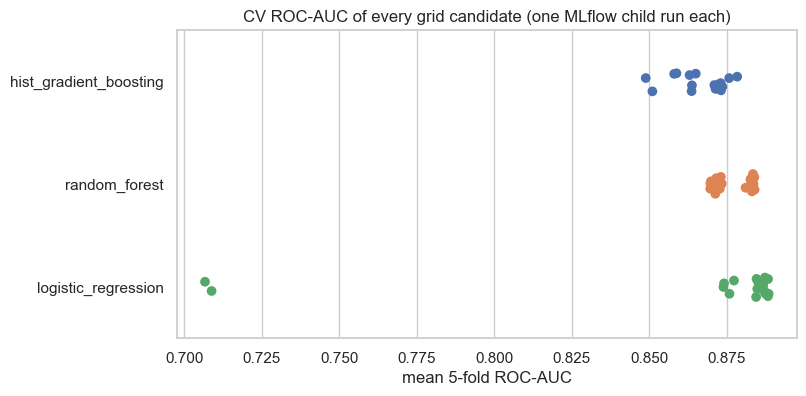

In [6]:
children = runs[runs["tags.mlflow.parentRunId"].notna()]
fig, ax = plt.subplots(figsize=(8, 4))
sns.stripplot(data=children, x="metrics.cv_roc_auc", y="tags.model_family", hue="tags.model_family",
              size=7, ax=ax, legend=False)
ax.set_title("CV ROC-AUC of every grid candidate (one MLflow child run each)")
ax.set_xlabel("mean 5-fold ROC-AUC"); ax.set_ylabel("")
plt.show()

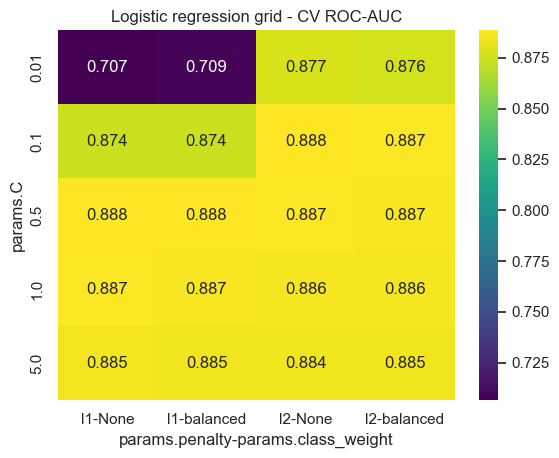

In [7]:
lr = children[children["tags.model_family"] == "logistic_regression"]
pivot = lr.pivot_table(index="params.C", columns=["params.penalty", "params.class_weight"],
                       values="metrics.cv_roc_auc")
sns.heatmap(pivot, annot=True, fmt=".3f", cmap="viridis")
plt.title("Logistic regression grid - CV ROC-AUC"); plt.show()

## 6. Hold-out diagnostics of the tuned models

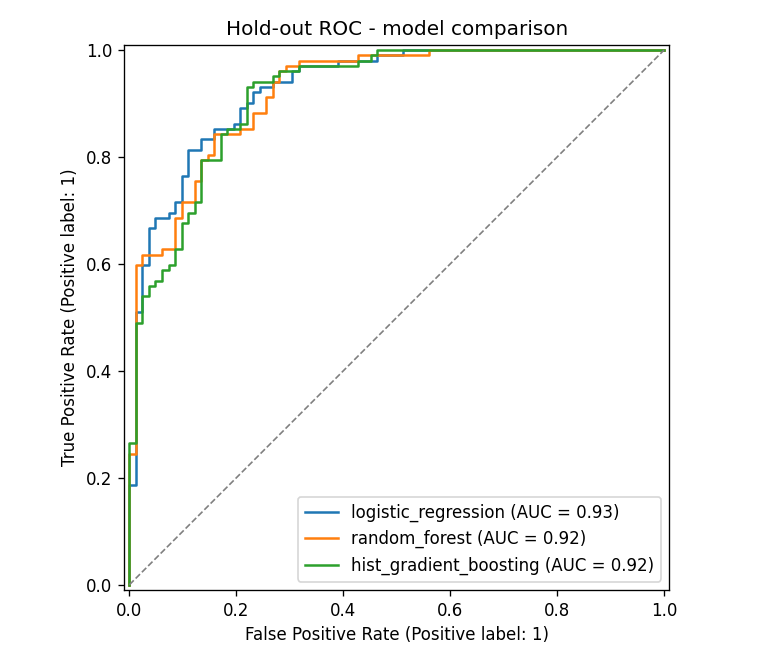

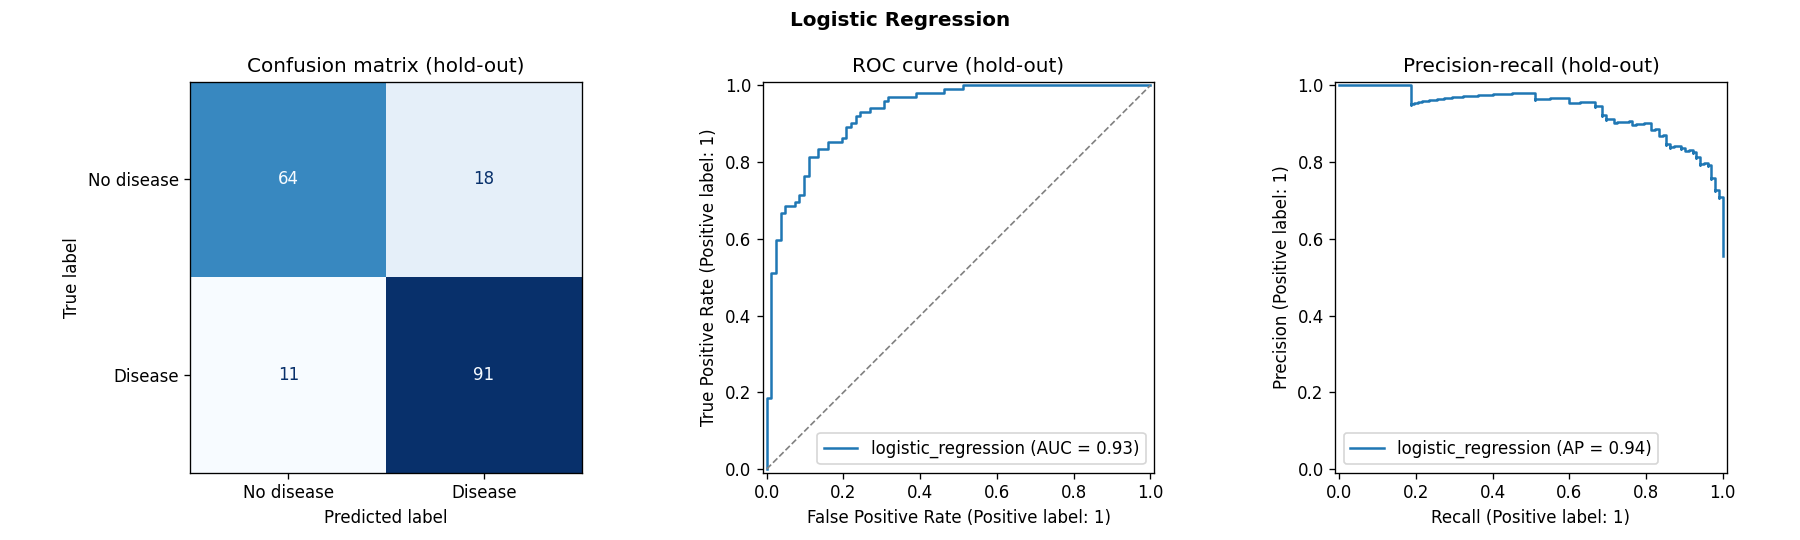

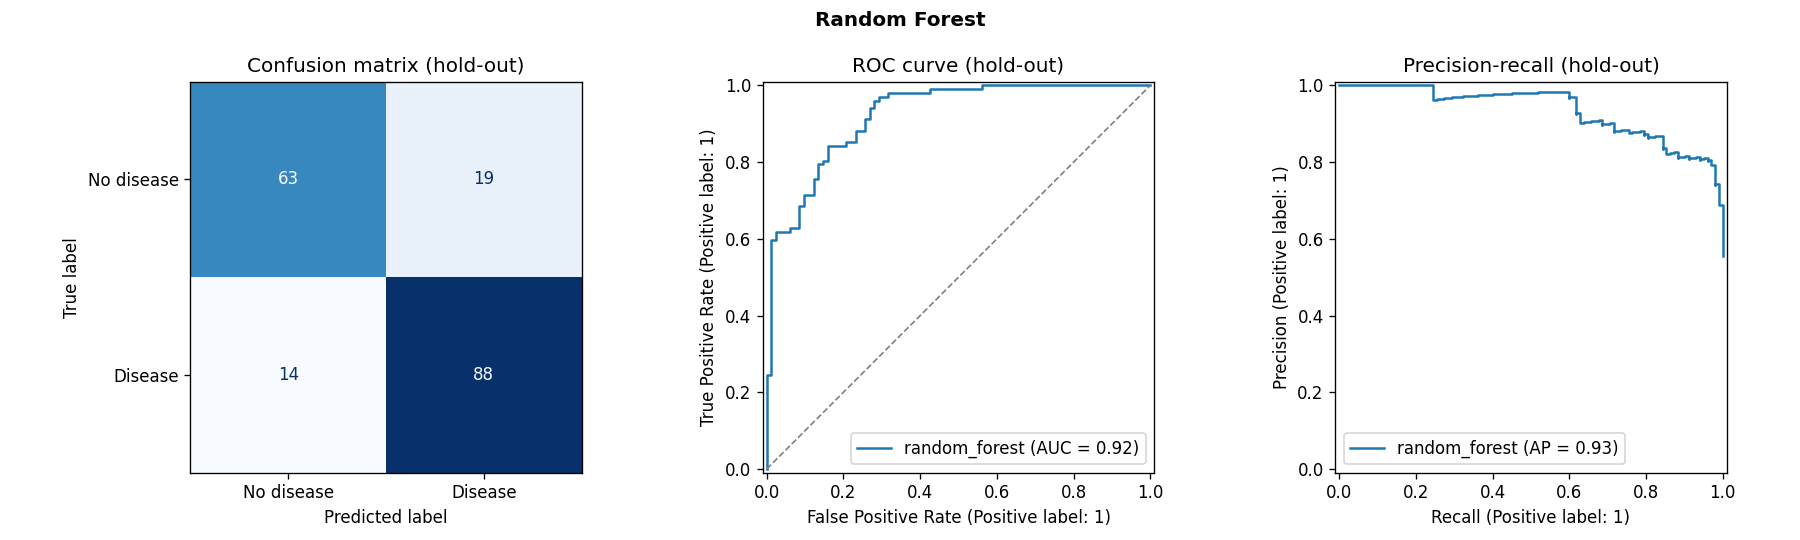

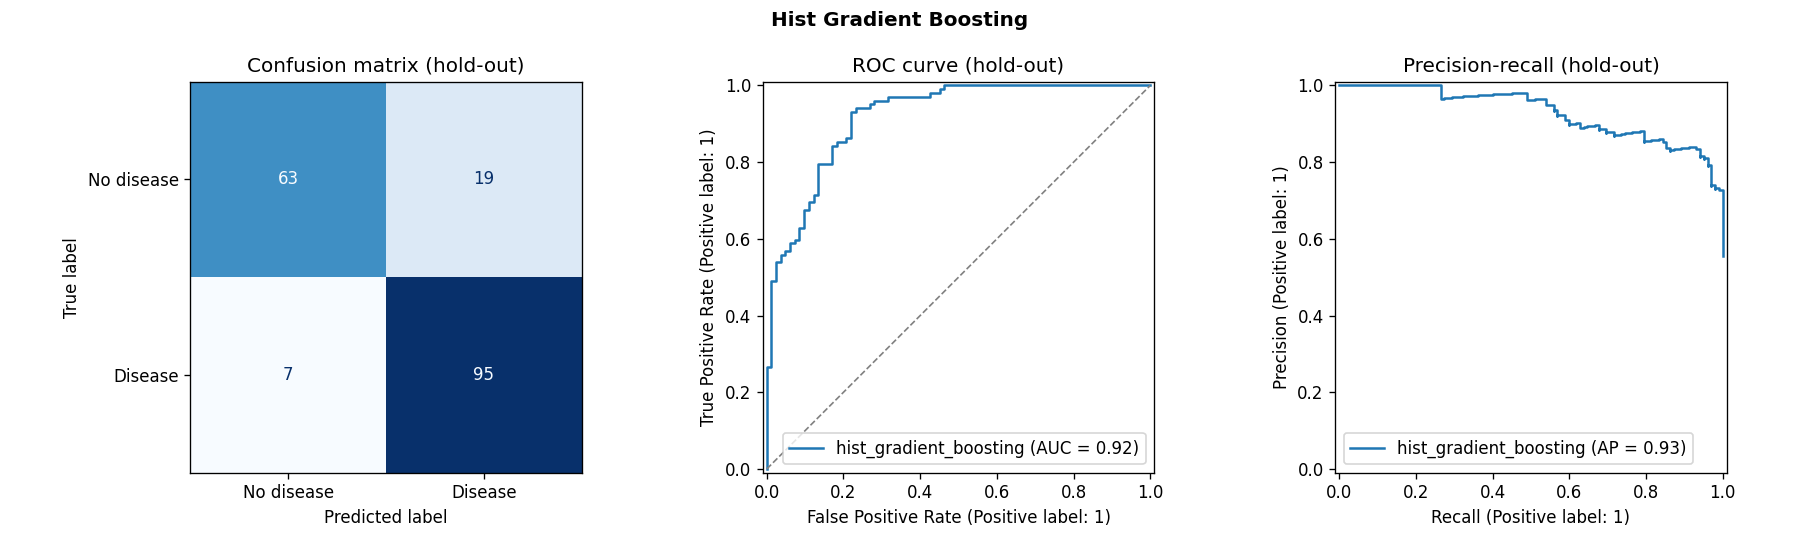

In [8]:
display(Image(str(config.FIGURES_DIR / "model_comparison_roc.png")))
for name in ["logistic_regression", "random_forest", "hist_gradient_boosting"]:
    display(Image(str(config.FIGURES_DIR / "models" / f"{name}_diagnostics.png")))

In [9]:
import json
meta = json.loads(config.MODEL_META.read_text())
print(json.dumps(meta, indent=2))

{
  "model_name": "logistic_regression",
  "model_version": "1.0.0",
  "mlflow_run_id": "fd15726cd0254b4eb14e971f36b32edb",
  "trained_at": "2026-10-08T14:50:17+00:00",
  "features": [
    "age",
    "trestbps",
    "chol",
    "thalach",
    "oldpeak",
    "ca",
    "sex",
    "fbs",
    "exang",
    "cp",
    "restecg",
    "slope",
    "thal"
  ],
  "best_params": {
    "C": 0.5,
    "class_weight": null,
    "penalty": "l1"
  },
  "metrics": {
    "cv_roc_auc": 0.8884,
    "cv_roc_auc_std": 0.0497,
    "cv_accuracy": 0.8202,
    "cv_precision": 0.8276,
    "cv_recall": 0.8597,
    "cv_f1": 0.8425,
    "test_roc_auc": 0.9299,
    "test_accuracy": 0.8424,
    "test_precision": 0.8349,
    "test_recall": 0.8922,
    "test_f1": 0.8626
  },
  "n_training_rows": 918,
  "threshold": 0.5
}


## 7. Model selection rationale
* All three tuned families land within ~0.01 CV ROC-AUC of each other - the CV standard deviation (~0.05) is larger than the gap.
* **Logistic regression (L1, C = 0.5)** has the best mean CV ROC-AUC, is the simplest, calibrates well, trains in milliseconds and gives directly interpretable coefficients (important in a clinical setting), so it is the champion.
* The L1 penalty zeroes out 8 of the 31 engineered features (e.g. all `restecg` levels, `thal = 6`) - a built-in feature selection.
* Recall (~0.86-0.89) is prioritised over precision in the report because missing a diseased patient is costlier than a false alarm; the API exposes the raw probability and a risk band so the threshold can be tuned downstream.

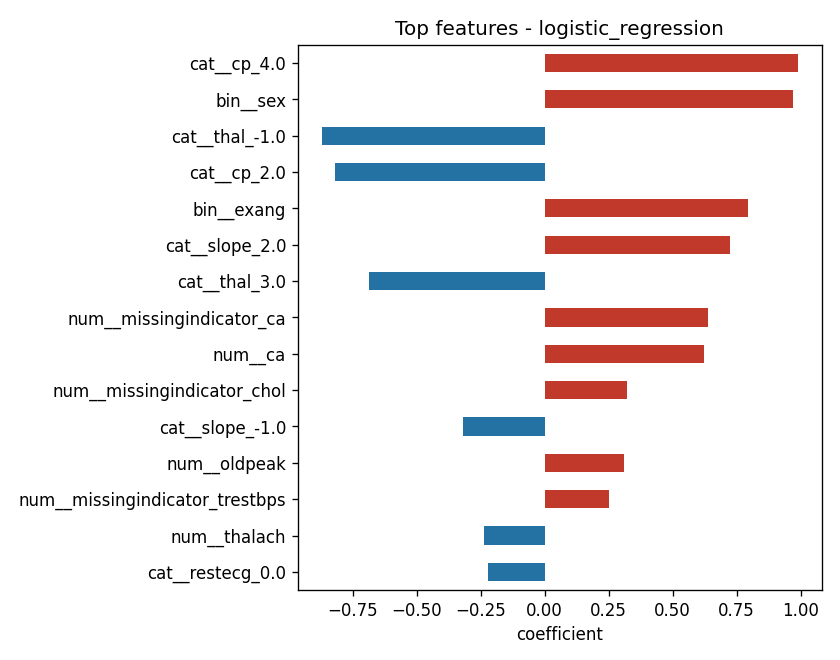

In [10]:
display(Image(str(config.FIGURES_DIR / "models" / "logistic_regression_features.png")))